# Creating Cohorts of Songs — Rolling Stones on Spotify

**Goal:** explore the audio features of every Rolling Stones track on Spotify and group the songs into cohorts (clusters)
of similar songs that can feed a recommendation system.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42

df = pd.read_csv("../rolling_stones_spotify.csv")
print(df.shape)
df.head()

(1610, 18)


,Unnamed: 0,name,album,release_date,track_number,id,uri,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms
0,0,Concert Intro Music - Live,Licked Live In NYC,2022-06-10,1,2IEkywLJ4ykbhi1yRQvmsT,spotify:track:2IEkywLJ4ykbhi1yRQvmsT,0.0824,0.463,0.993,0.996000,0.932,-12.913,0.1100,118.001,0.0302,33,48640
1,1,Street Fighting Man - Live,Licked Live In NYC,2022-06-10,2,6GVgVJBKkGJoRfarYRvGTU,spotify:track:6GVgVJBKkGJoRfarYRvGTU,0.4370,0.326,0.965,0.233000,0.961,-4.803,0.0759,131.455,0.3180,34,253173
2,2,Start Me Up - Live,Licked Live In NYC,2022-06-10,3,1Lu761pZ0dBTGpzxaQoZNW,spotify:track:1Lu761pZ0dBTGpzxaQoZNW,0.4160,0.386,0.969,0.400000,0.956,-4.936,0.1150,130.066,0.3130,34,263160
3,3,If You Can't Rock Me - Live,Licked Live In NYC,2022-06-10,4,1agTQzOTUnGNggyckEqiDH,spotify:track:1agTQzOTUnGNggyckEqiDH,0.5670,0.369,0.985,0.000107,0.895,-5.535,0.1930,132.994,0.1470,32,305880
4,4,Don’t Stop - Live,Licked Live In NYC,2022-06-10,5,7piGJR8YndQBQWVXv6KtQw,spotify:track:7piGJR8YndQBQWVXv6KtQw,0.4000,0.303,0.969,0.055900,0.966,-5.098,0.0930,130.533,0.2060,32,305106


## 1. Initial inspection & data cleaning

In [2]:
df = df.drop(columns=["Unnamed: 0"])           # leftover index column
df["release_date"] = pd.to_datetime(df["release_date"])
df.info()
print("\nMissing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Spotify ids:", df["id"].duplicated().sum())
print("Same song name on the same album:", df.duplicated(["name", "album"]).sum())

<class 'pandas.DataFrame'>
RangeIndex: 1610 entries, 0 to 1609
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   name              1610 non-null   str           
 1   album             1610 non-null   str           
 2   release_date      1610 non-null   datetime64[us]
 3   track_number      1610 non-null   int64         
 4   id                1610 non-null   str           
 5   uri               1610 non-null   str           
 6   acousticness      1610 non-null   float64       
 7   danceability      1610 non-null   float64       
 8   energy            1610 non-null   float64       
 9   instrumentalness  1610 non-null   float64       
 10  liveness          1610 non-null   float64       
 11  loudness          1610 non-null   float64       
 12  speechiness       1610 non-null   float64       
 13  tempo             1610 non-null   float64       
 14  valence           1610 non-null   f

* No missing values and every `id` is unique.
* However, **102 rows repeat a song name within the same album** (deluxe/re-issue track lists that repeat a song). These are duplicates for
  cohort purposes, so the most popular version is kept.

In [3]:
df = df.sort_values("popularity", ascending=False).drop_duplicates(["name", "album"]).sort_index()
print("Rows after de-duplication:", len(df))

Rows after de-duplication: 1508


In [4]:
features = ["acousticness", "danceability", "energy", "instrumentalness", "liveness",
            "loudness", "speechiness", "tempo", "valence", "duration_ms"]
# Irrelevant / erroneous values: values outside their documented ranges
checks = {
    "0-1 features out of range": ((df[["acousticness", "danceability", "energy", "instrumentalness", "liveness", "speechiness", "valence"]] < 0) |
                                  (df[["acousticness", "danceability", "energy", "instrumentalness", "liveness", "speechiness", "valence"]] > 1)).sum().sum(),
    "loudness > 0 dB or < -60": ((df["loudness"] > 0) | (df["loudness"] < -60)).sum(),
    "tempo == 0": (df["tempo"] == 0).sum(),
    "popularity outside 0-100": ((df["popularity"] < 0) | (df["popularity"] > 100)).sum(),
    "duration <= 0": (df["duration_ms"] <= 0).sum(),
}
checks

{'0-1 features out of range': np.int64(0),
 'loudness > 0 dB or < -60': np.int64(0),
 'tempo == 0': np.int64(0),
 'popularity outside 0-100': np.int64(0),
 'duration <= 0': np.int64(0)}

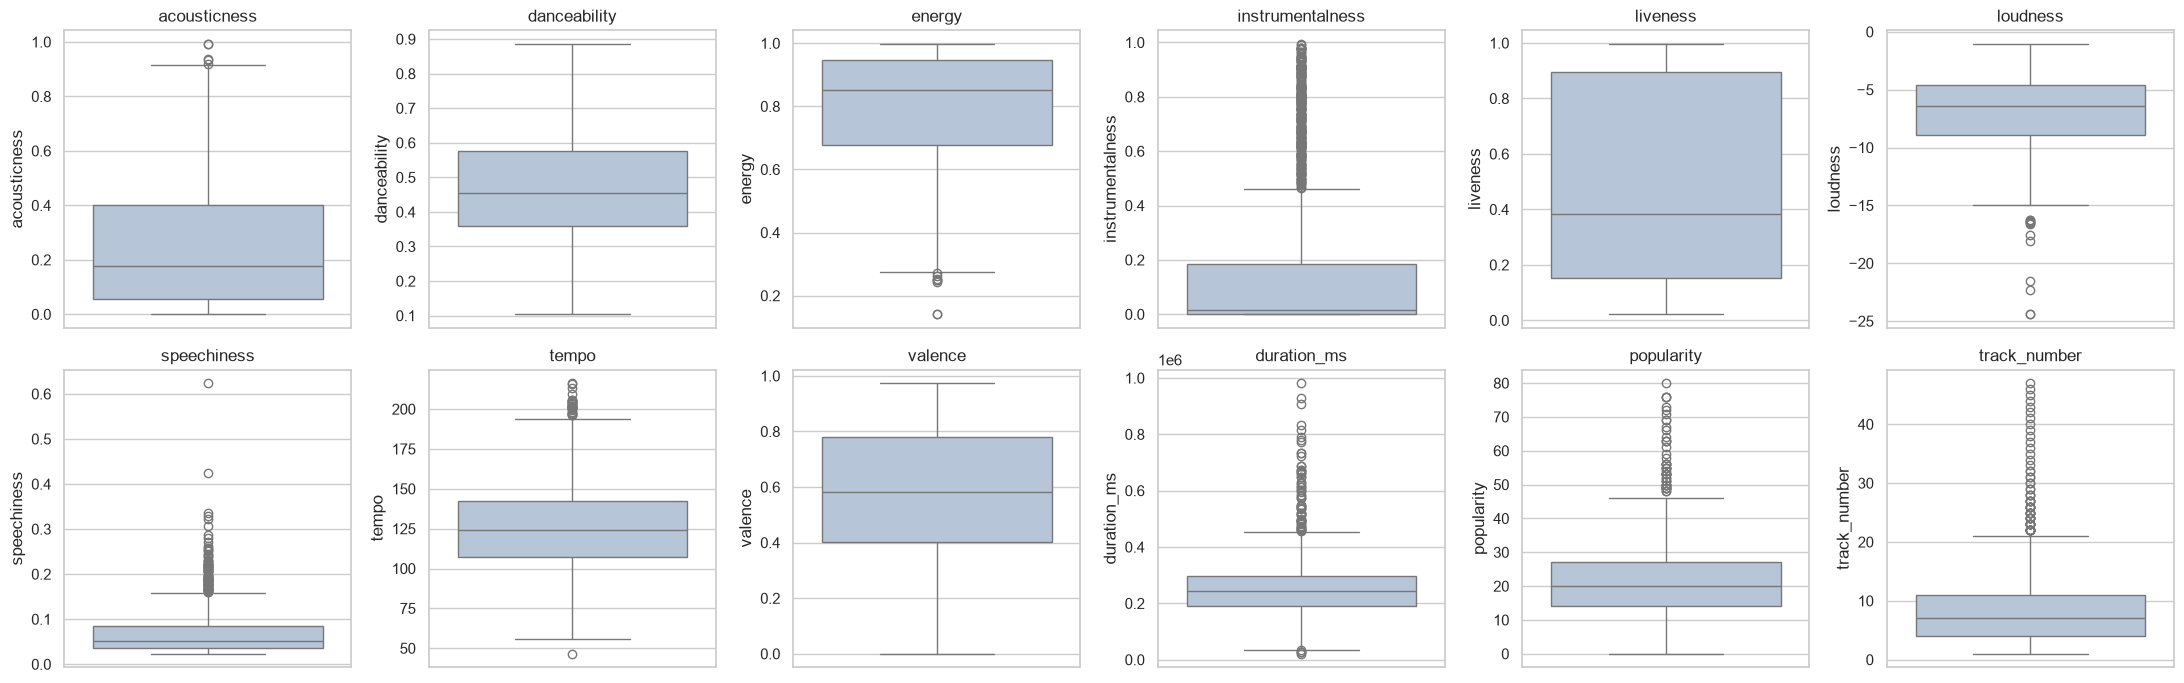

In [5]:
fig, axes = plt.subplots(2, 6, figsize=(22, 7))
for ax, c in zip(axes.ravel(), features + ["popularity", "track_number"]):
    sns.boxplot(y=df[c], ax=ax, color="lightsteelblue"); ax.set_title(c)
plt.tight_layout(); plt.show()

**Outliers:** `duration_ms` has very long tracks (up to ~16 min live jams), `speechiness` has a few spoken intros, and `instrumentalness` is heavily
skewed. These are *genuine* musical properties (not errors), so they are kept; extreme durations are capped at the 1st/99th percentile for clustering
so that a handful of jams do not dominate distances.

In [6]:
df["duration_min"] = df["duration_ms"] / 60000
df["year"] = df["release_date"].dt.year
df["is_live"] = df["album"].str.contains("live|Live|LIVE|Licked|Stripped|Ya-Yas|Concert", regex=True) | (df["liveness"] > 0.8)
lo, hi = df["duration_ms"].quantile([0.01, 0.99])
df["duration_ms_capped"] = df["duration_ms"].clip(lo, hi)
print(f"Live recordings: {df['is_live'].mean():.0%} of tracks")

Live recordings: 41% of tracks


## 2. Exploratory data analysis & feature engineering
### 2a. Which two albums should be recommended? (number of popular songs per album)
A song is "popular" if its popularity is in the top quartile of the catalogue.

Popularity threshold (75th percentile): 27


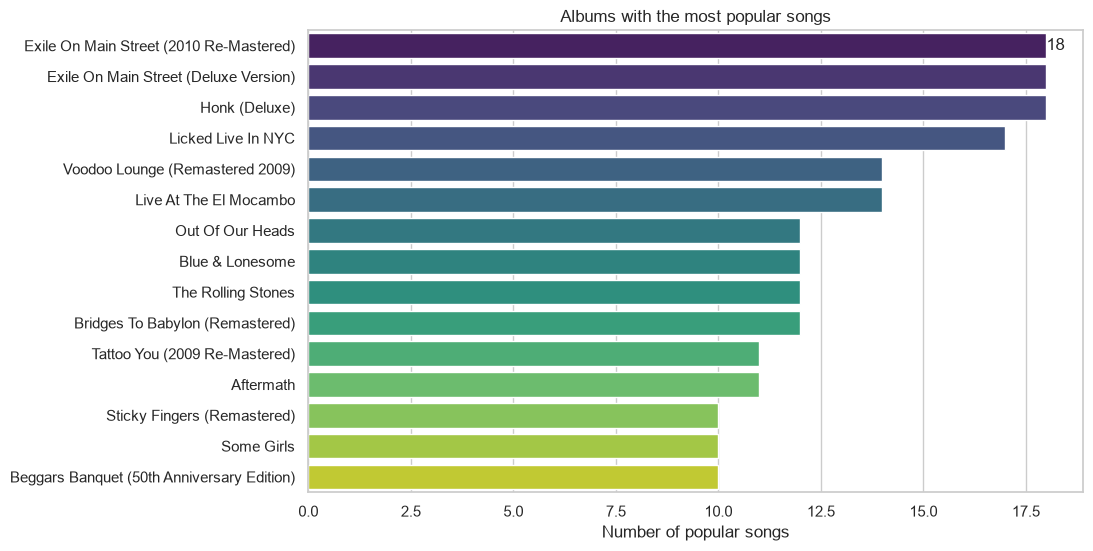

,popular_songs,tracks,avg_popularity,year
album,,,,
Exile On Main Street (2010 Re-Mastered),18,18,44.166667,1972
Exile On Main Street (Deluxe Version),18,28,29.964286,1972
Honk (Deluxe),18,47,26.212766,2019
Licked Live In NYC,17,23,28.608696,2022
Voodoo Lounge (Remastered 2009),14,15,34.000000,1994
Live At The El Mocambo,14,23,27.260870,2022
Out Of Our Heads,12,12,39.583333,1965
Blue & Lonesome,12,12,34.916667,2016
The Rolling Stones,12,12,34.166667,1964


In [7]:
pop_threshold = df["popularity"].quantile(0.75)
df["is_popular"] = df["popularity"] >= pop_threshold
album_pop = (df.groupby("album").agg(popular_songs=("is_popular", "sum"), tracks=("name", "count"),
                                     avg_popularity=("popularity", "mean"), year=("year", "first"))
             .sort_values(["popular_songs", "avg_popularity"], ascending=False))
print(f"Popularity threshold (75th percentile): {pop_threshold:.0f}")

top = album_pop.head(15)
plt.figure(figsize=(10, 6))
ax = sns.barplot(y=top.index, x=top["popular_songs"], palette="viridis")
ax.bar_label(ax.containers[0]); plt.title("Albums with the most popular songs"); plt.xlabel("Number of popular songs"); plt.ylabel("")
plt.show()
album_pop.head(10)

In [8]:
# Several albums appear in multiple editions (remastered, deluxe...). Group editions under one base title
# so that we recommend two *different* albums.
df["album_base"] = df["album"].str.replace(r"\s*[\(\[].*?[\)\]]", "", regex=True).str.strip()
base_pop = (df.groupby("album_base").agg(popular_songs=("is_popular", "sum"), avg_popularity=("popularity", "mean"),
                                         editions=("album", "nunique"))
            .sort_values(["popular_songs", "avg_popularity"], ascending=False))
display(base_pop.head(8))
rec = base_pop.head(2).index.tolist()
print("Recommended albums:", rec)

,popular_songs,avg_popularity,editions
album_base,,,
Exile On Main Street,36,23.840000,3
Sticky Fingers,23,28.079365,3
Tattoo You,23,24.278481,3
Goats Head Soup,22,26.280702,3
Let It Bleed,18,44.388889,2
Honk,18,26.212766,1
Licked Live In NYC,17,28.608696,1
Voodoo Lounge,14,34.000000,1


Recommended albums: ['Exile On Main Street', 'Sticky Fingers']


### 2b. Feature distributions and patterns

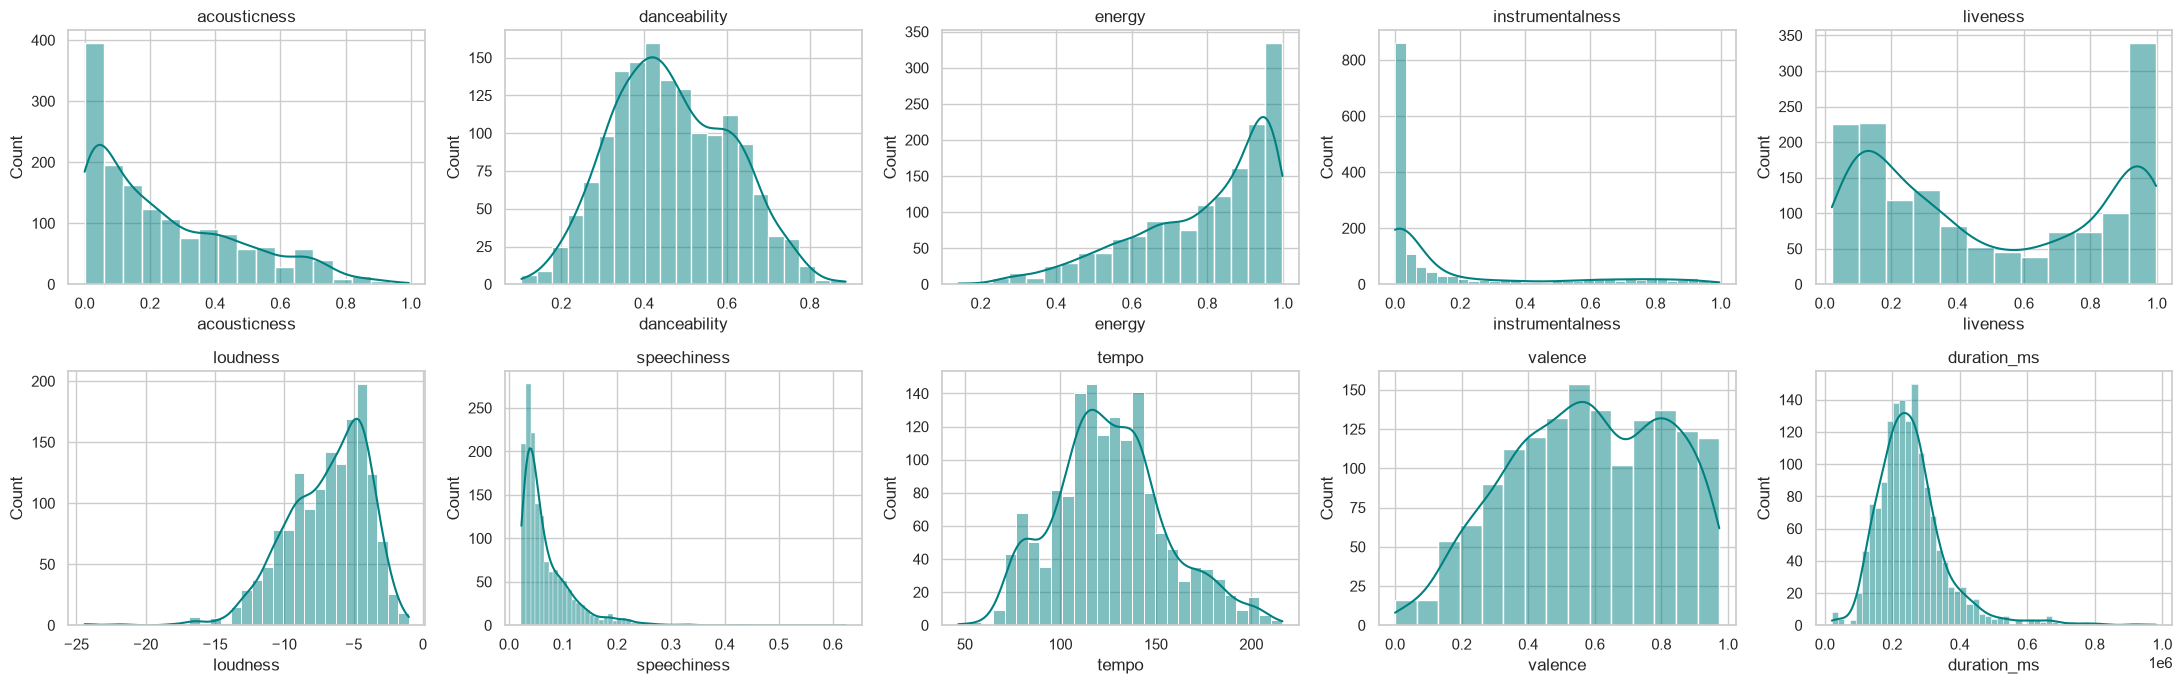

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(22, 7))
for ax, c in zip(axes.ravel(), features):
    sns.histplot(df[c], kde=True, ax=ax, color="teal"); ax.set_title(c)
plt.tight_layout(); plt.show()

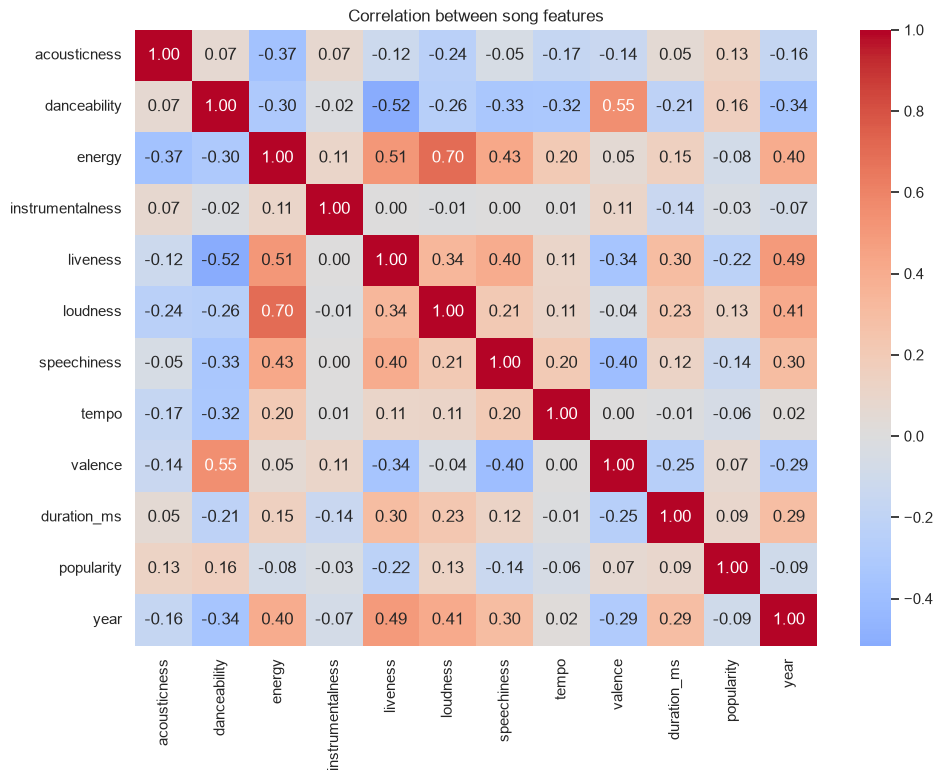

In [10]:
plt.figure(figsize=(11, 8))
sns.heatmap(df[features + ["popularity", "year"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between song features"); plt.show()

**Patterns:** the Stones catalogue is **high-energy and loud** (median energy ≈ 0.85) with moderate danceability and mostly positive valence.
A large share of tracks are **live recordings** (bimodal `liveness`). Energy and loudness are strongly correlated (≈ 0.7), and both are
negatively correlated with acousticness — the classic "loud rock vs acoustic ballad" axis. Danceability goes with valence (happier songs are more danceable).

### 2c. What drives popularity, and how has it changed over time?

liveness           -0.223
speechiness        -0.136
year               -0.092
energy             -0.080
tempo              -0.059
instrumentalness   -0.032
valence             0.069
duration_ms         0.091
acousticness        0.126
loudness            0.129
danceability        0.162
dtype: float64
is_live
studio    24.1
live      17.9
Name: popularity, dtype: float64


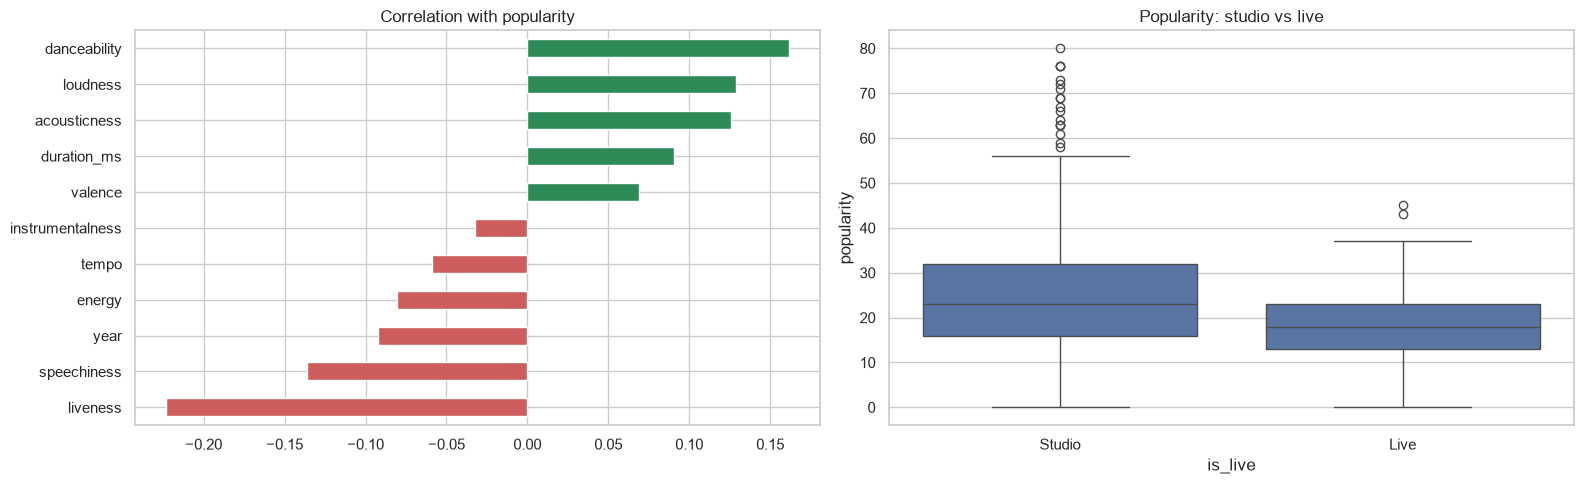

In [11]:
corr_pop = df[features + ["year"]].corrwith(df["popularity"]).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
print(corr_pop.round(3))
print(df.groupby("is_live")["popularity"].mean().rename({False: "studio", True: "live"}).round(1))
corr_pop.plot.barh(ax=axes[0], color=np.where(corr_pop > 0, "seagreen", "indianred")); axes[0].set_title("Correlation with popularity")
sns.boxplot(data=df, x="is_live", y="popularity", ax=axes[1]); axes[1].set_title("Popularity: studio vs live"); axes[1].set_xticklabels(["Studio", "Live"])
plt.tight_layout(); plt.show()

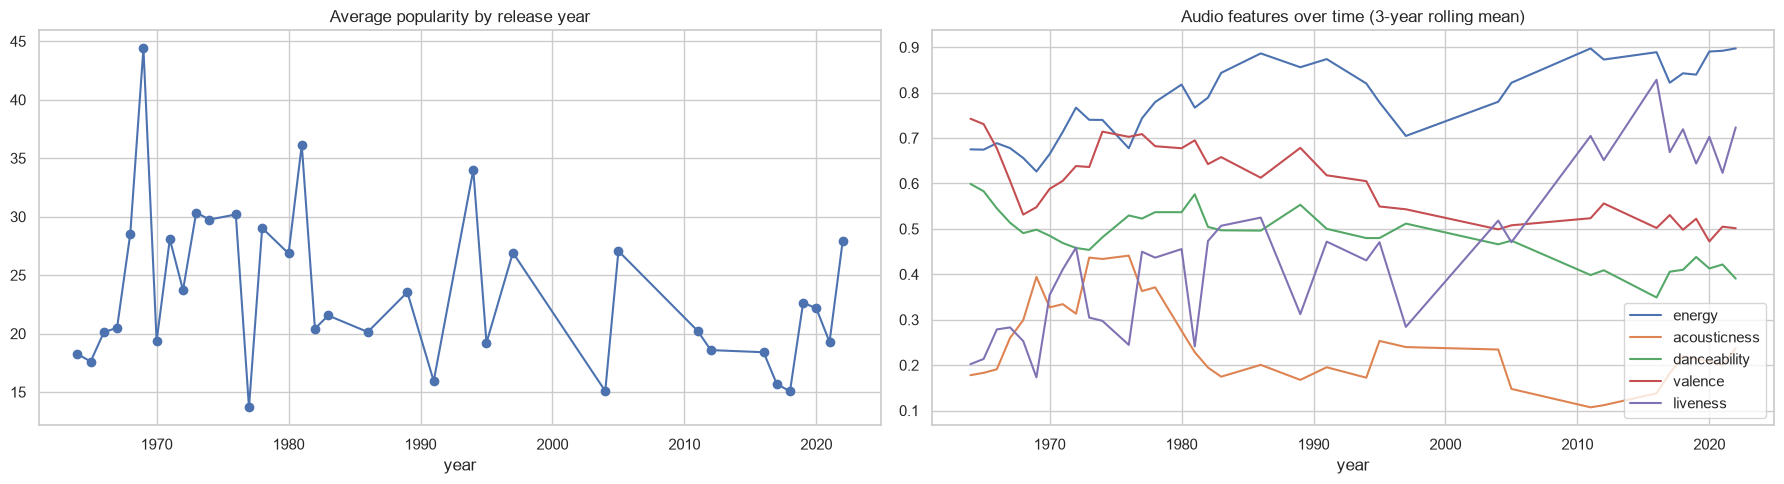

,popularity,energy,acousticness,danceability,valence,liveness
decade,,,,,,
1960s,20.86,0.67,0.26,0.53,0.64,0.24
1970s,24.47,0.78,0.35,0.48,0.66,0.43
1980s,25.13,0.81,0.18,0.54,0.67,0.35
1990s,22.23,0.78,0.23,0.49,0.54,0.46
2000s,18.18,0.90,0.16,0.40,0.46,0.74
2010s,18.51,0.85,0.19,0.41,0.51,0.69
2020s,22.36,0.90,0.23,0.40,0.50,0.70


In [12]:
df["decade"] = (df["year"] // 10 * 10).astype(str) + "s"
yearly = df.groupby("year").agg(popularity=("popularity", "mean"), energy=("energy", "mean"), acousticness=("acousticness", "mean"),
                                 danceability=("danceability", "mean"), valence=("valence", "mean"), liveness=("liveness", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
yearly["popularity"].plot(ax=axes[0], marker="o"); axes[0].set_title("Average popularity by release year")
yearly[["energy", "acousticness", "danceability", "valence", "liveness"]].rolling(3, min_periods=1).mean().plot(ax=axes[1])
axes[1].set_title("Audio features over time (3-year rolling mean)")
plt.tight_layout(); plt.show()
df.groupby("decade")[["popularity", "energy", "acousticness", "danceability", "valence", "liveness"]].mean().round(2)

**Findings:**
* **Live recordings are clearly less popular** than studio tracks; `liveness` has the strongest negative correlation with popularity.
* Popular songs tend to be more **danceable**, slightly louder and more acoustic, and less **speechy** (spoken intros/crowd banter). Correlations are weak overall (|r| < 0.25), so popularity depends mostly on factors outside the audio features (fame of the song).
* Over time, the band moved from the acoustic, lower-energy sound of the 1960s toward louder, more energetic recordings; recent releases
  (mostly live albums and re-issues) are less popular, while 1960s-70s classics remain the most streamed.

### 2d. Why dimensionality reduction?
* The 10 audio features are partly **redundant** (energy ↔ loudness ↔ acousticness), and distance-based clustering suffers when correlated
  features double-count the same information and when dimensions grow (the *curse of dimensionality*).
* **PCA** combines correlated features into orthogonal components, removes noise, speeds up clustering and lets us **visualise** clusters in 2-D.
* Below, PCA shows how much variance each component explains.

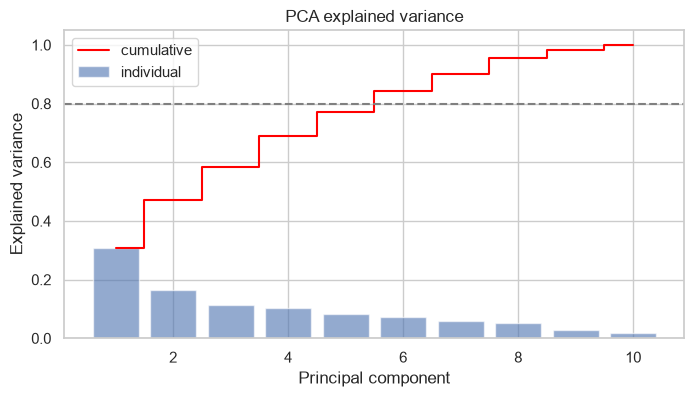

6 components explain 84% of the variance


,PC1,PC2,PC3
acousticness,-0.16,-0.47,0.05
danceability,-0.41,0.25,-0.25
energy,0.43,0.41,-0.08
instrumentalness,-0.01,0.15,0.52
liveness,0.44,-0.09,-0.06
loudness,0.37,0.33,-0.29
speechiness,0.37,-0.12,0.21
tempo,0.20,0.14,0.50
valence,-0.27,0.57,-0.07
duration_ms_capped,0.23,-0.25,-0.52


In [13]:
cluster_features = ["acousticness", "danceability", "energy", "instrumentalness", "liveness",
                    "loudness", "speechiness", "tempo", "valence", "duration_ms_capped"]
X = StandardScaler().fit_transform(df[cluster_features])
pca = PCA().fit(X)
cum = np.cumsum(pca.explained_variance_ratio_)
plt.figure(figsize=(8, 4))
plt.bar(range(1, len(cum) + 1), pca.explained_variance_ratio_, alpha=0.6, label="individual")
plt.step(range(1, len(cum) + 1), cum, where="mid", color="red", label="cumulative"); plt.axhline(0.8, ls="--", color="grey")
plt.xlabel("Principal component"); plt.ylabel("Explained variance"); plt.legend(); plt.title("PCA explained variance"); plt.show()
n_comp = int(np.argmax(cum >= 0.8) + 1)
print(f"{n_comp} components explain {cum[n_comp-1]:.0%} of the variance")
loadings = pd.DataFrame(pca.components_[:3].T, index=cluster_features, columns=["PC1", "PC2", "PC3"]).round(2)
loadings

PC1 is essentially a **"live energy vs. acoustic studio"** axis (energy, loudness, liveness vs acousticness) and PC2 a **"danceable/happy"** axis
(danceability, valence). Keeping enough components for ~80% variance preserves most of the information with fewer, uncorrelated dimensions.

## 3. Cluster analysis
### 3a. Choosing the number of clusters (elbow + silhouette)

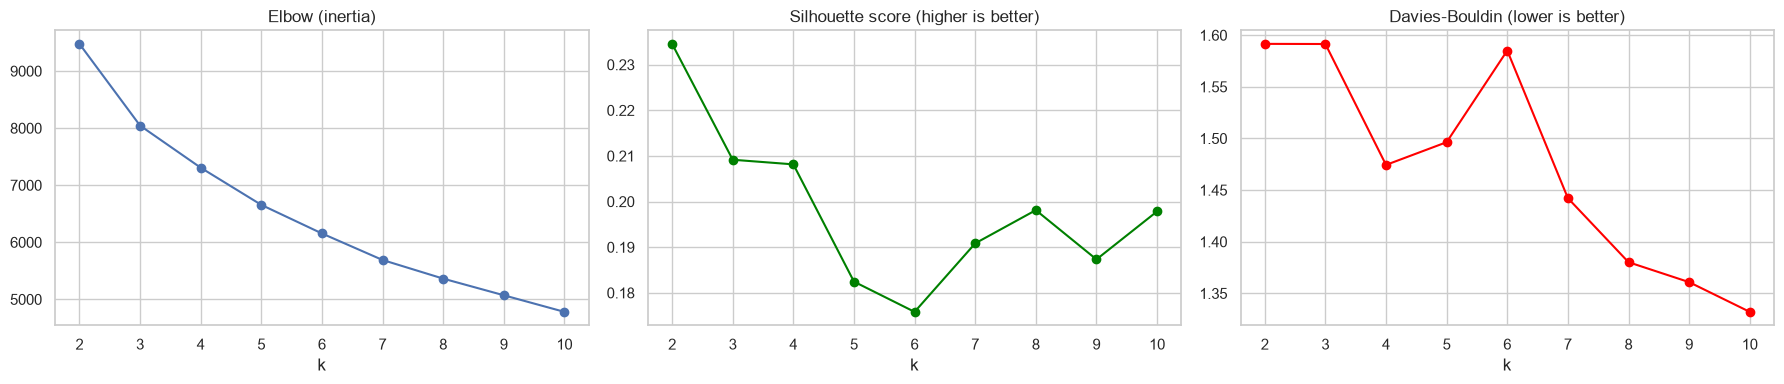

,k,inertia,silhouette,davies_bouldin
0,2,9476.658,0.235,1.592
1,3,8044.562,0.209,1.591
2,4,7306.827,0.208,1.474
3,5,6655.439,0.182,1.496
4,6,6154.483,0.176,1.585
5,7,5689.605,0.191,1.442
6,8,5362.951,0.198,1.380
7,9,5071.408,0.187,1.361
8,10,4780.443,0.198,1.332


In [14]:
X_pca = PCA(n_components=n_comp, random_state=RANDOM_STATE).fit_transform(X)
ks = range(2, 11)
inertia, sil, dbi = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_pca)
    inertia.append(km.inertia_); sil.append(silhouette_score(X_pca, km.labels_)); dbi.append(davies_bouldin_score(X_pca, km.labels_))
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(ks, inertia, "o-"); axes[0].set_title("Elbow (inertia)")
axes[1].plot(ks, sil, "o-", color="green"); axes[1].set_title("Silhouette score (higher is better)")
axes[2].plot(ks, dbi, "o-", color="red"); axes[2].set_title("Davies-Bouldin (lower is better)")
for a in axes: a.set_xlabel("k")
plt.tight_layout(); plt.show()
pd.DataFrame({"k": list(ks), "inertia": inertia, "silhouette": sil, "davies_bouldin": dbi}).round(3)

The elbow flattens around **k = 4**, where the silhouette is still high relative to larger k and Davies-Bouldin is low.
Four cohorts are also easy to interpret for a recommendation product, so **k = 4** is used.

In [15]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=50, random_state=RANDOM_STATE).fit(X_pca)
df["cluster"] = kmeans.labels_
agg = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X_pca)
print(f"K-Means silhouette:        {silhouette_score(X_pca, df['cluster']):.3f}")
print(f"Agglomerative silhouette:  {silhouette_score(X_pca, agg.labels_):.3f}")
print(df["cluster"].value_counts().sort_index())

K-Means silhouette:        0.207
Agglomerative silhouette:  0.157
cluster
0    330
1    484
2    500
3    194
Name: count, dtype: int64


K-Means is chosen (comparable or better silhouette than Ward agglomerative, scales well and gives centroids that can be used to assign new songs).

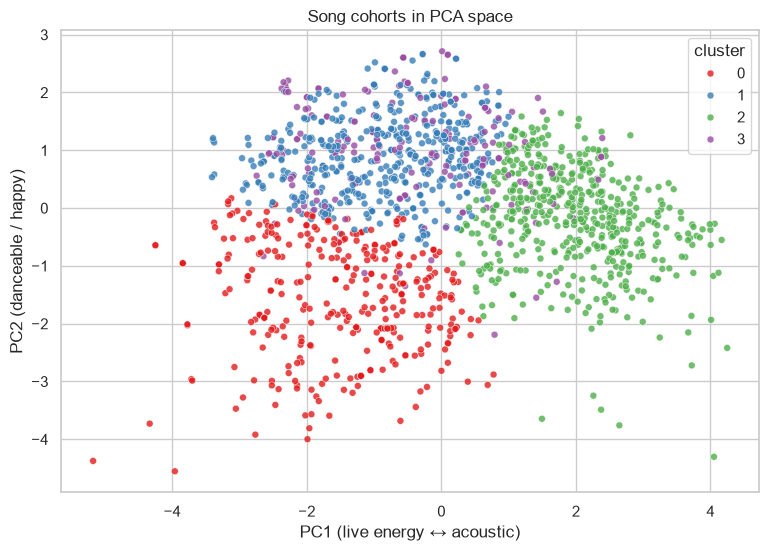

In [16]:
pcs = PCA(n_components=2).fit_transform(X)
plt.figure(figsize=(9, 6))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=df["cluster"], palette="Set1", s=25, alpha=0.8)
plt.xlabel("PC1 (live energy ↔ acoustic)"); plt.ylabel("PC2 (danceable / happy)"); plt.title("Song cohorts in PCA space"); plt.show()

### 3b. Defining each cluster

,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,duration_min,popularity,n_songs,live_%
cluster,,,,,,,,,,,,,
0,0.465,0.486,0.556,0.083,0.298,-9.753,0.047,113.226,0.454,4.146,23.433,330,19.0
1,0.155,0.554,0.806,0.057,0.298,-6.754,0.049,123.085,0.760,3.821,23.504,484,16.0
2,0.189,0.356,0.928,0.110,0.842,-5.178,0.108,137.714,0.440,5.186,18.422,500,87.0
3,0.247,0.499,0.828,0.744,0.426,-6.860,0.054,125.909,0.721,3.348,21.407,194,25.0


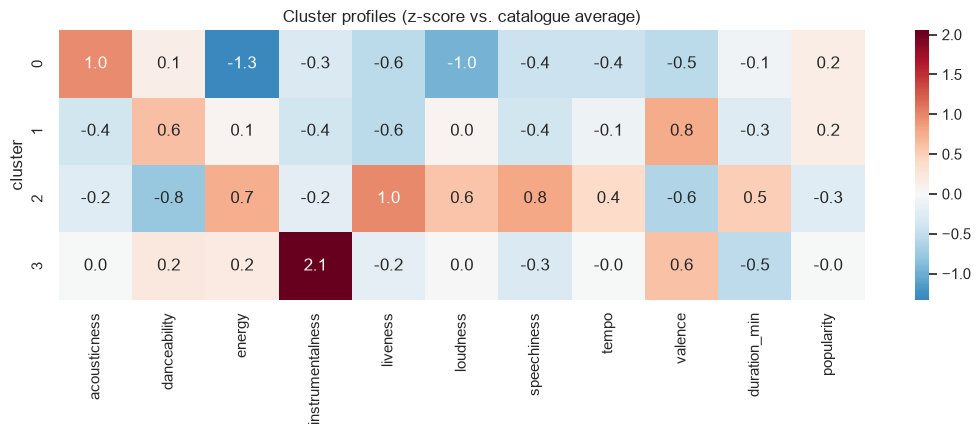

In [17]:
profile = df.groupby("cluster")[cluster_features[:-1] + ["duration_min", "popularity"]].mean()
profile["n_songs"] = df["cluster"].value_counts().sort_index()
profile["live_%"] = (df.groupby("cluster")["is_live"].mean() * 100).round(0)
display(profile.round(3))

z = (profile[cluster_features[:-1] + ["duration_min", "popularity"]] - df[cluster_features[:-1] + ["duration_min", "popularity"]].mean()) / df[cluster_features[:-1] + ["duration_min", "popularity"]].std()
plt.figure(figsize=(13, 3.5))
sns.heatmap(z, annot=True, fmt=".1f", cmap="RdBu_r", center=0)
plt.title("Cluster profiles (z-score vs. catalogue average)"); plt.show()

In [18]:
def describe(row):
    tags = []
    if row["liveness"] > 0.6: tags.append("live")
    if row["acousticness"] > 0.45: tags.append("acoustic")
    if row["energy"] > 0.85: tags.append("high-energy")
    elif row["energy"] < 0.6: tags.append("mellow")
    if row["danceability"] > 0.55: tags.append("danceable")
    if row["valence"] > 0.65: tags.append("upbeat")
    elif row["valence"] < 0.45: tags.append("dark")
    if row["instrumentalness"] > 0.3: tags.append("instrumental-heavy")
    if row["speechiness"] > 0.1: tags.append("spoken/talky")
    return ", ".join(tags) or "average rock"
profile["cohort"] = profile.apply(describe, axis=1)
for c, r in profile.iterrows():
    examples = df[df.cluster == c].nlargest(5, "popularity")["name"].tolist()
    print(f"Cluster {c} ({int(r.n_songs)} songs, avg popularity {r.popularity:.0f}): {r.cohort}\n   e.g. {examples}\n")

Cluster 0 (330 songs, avg popularity 23): acoustic, mellow
   e.g. ['Gimme Shelter', 'Sympathy For The Devil - 50th Anniversary Edition', 'Angie', 'Wild Horses - 2009 Mix', "You Can't Always Get What You Want"]

Cluster 1 (484 songs, avg popularity 24): danceable, upbeat
   e.g. ['Paint It, Black', 'Start Me Up - Remastered 2009', "(I Can't Get No) Satisfaction - Mono Version", 'Beast Of Burden - Remastered 1994', 'Miss You - Remastered']

Cluster 2 (500 songs, avg popularity 18): live, high-energy, dark, spoken/talky
   e.g. ['Loving Cup', 'Time Is On My Side - Mono Version / Organ Intro', 'Like A Rolling Stone - Live / Remastered 2009', 'Undercover (Of The Night) - Remastered 2009', 'Loving Cup']

Cluster 3 (194 songs, avg popularity 21): upbeat, instrumental-heavy
   e.g. ['Tumbling Dice', 'Get Off Of My Cloud - Mono Version', 'The Last Time - Mono Version', 'Rip This Joint', 'Happy']



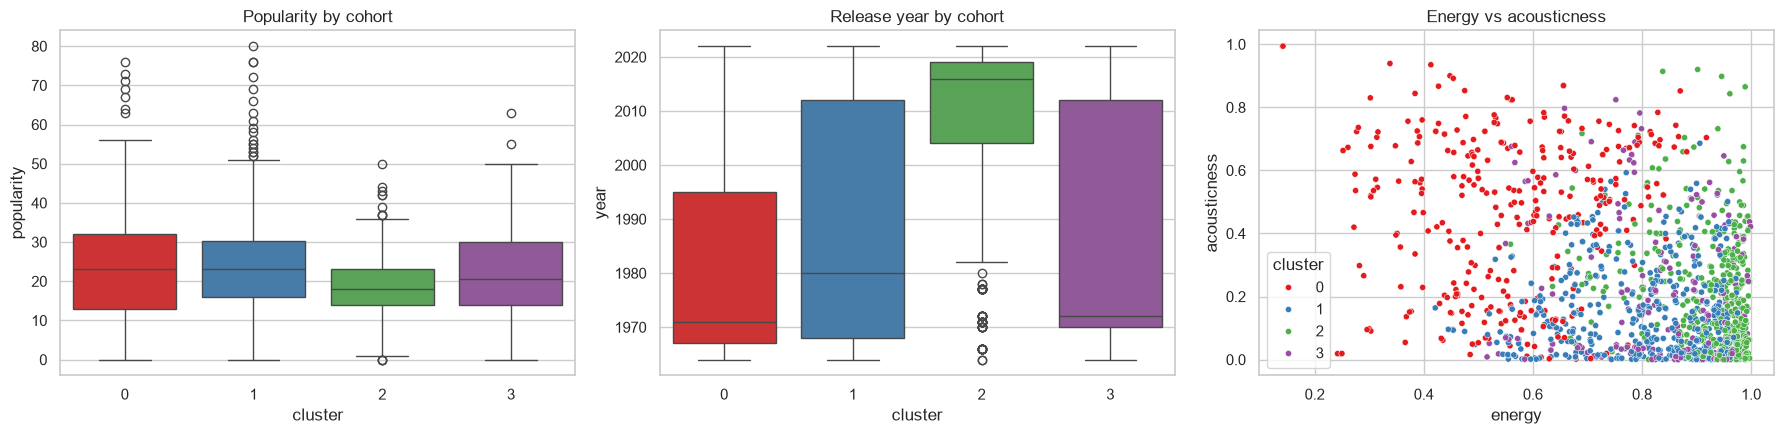

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.boxplot(data=df, x="cluster", y="popularity", ax=axes[0], palette="Set1"); axes[0].set_title("Popularity by cohort")
sns.boxplot(data=df, x="cluster", y="year", ax=axes[1], palette="Set1"); axes[1].set_title("Release year by cohort")
sns.scatterplot(data=df, x="energy", y="acousticness", hue="cluster", palette="Set1", ax=axes[2], s=20); axes[2].set_title("Energy vs acousticness")
plt.tight_layout(); plt.show()

## Conclusion
* Data was clean apart from **repeated tracks within albums** (removed) and genuine long-tail outliers (capped for clustering).
* The two albums to recommend are those with the **most top-quartile songs** (printed above).
* **Liveness** is the strongest (negative) driver of popularity — studio recordings dominate listening.
* PCA shows the features compress into a few meaningful axes (live-energy vs acoustic, danceable/happy), which makes clustering more robust.
* K-Means with **4 cohorts** separates the catalogue into interpretable groups that can power "more like this" recommendations:

| Cohort | Size | Character | Examples |
|---|---|---|---|
| 0 — Acoustic ballads | ~330 | high acousticness, low energy, quieter | Gimme Shelter, Angie, Wild Horses |
| 1 — Upbeat studio hits | ~480 | danceable, high valence, short | Paint It Black, Start Me Up, Satisfaction, Miss You |
| 2 — Live performances | ~500 | very high liveness & energy, longer, least popular | live versions from concert albums |
| 3 — Instrumental-heavy rockers | ~190 | high instrumentalness, upbeat | Tumbling Dice, Rip This Joint, Happy |